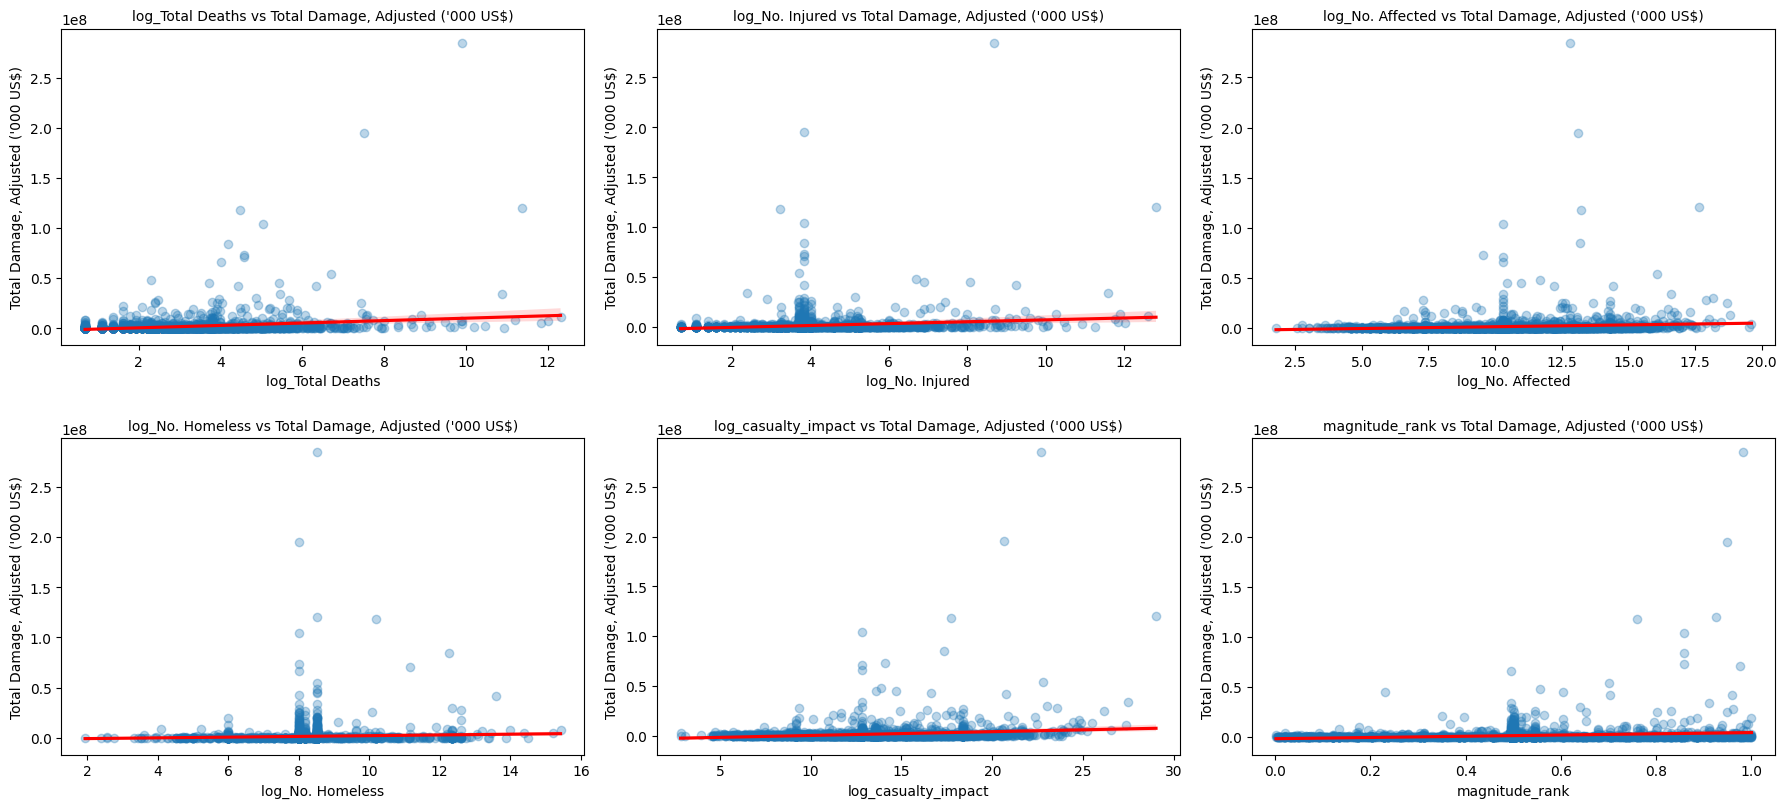

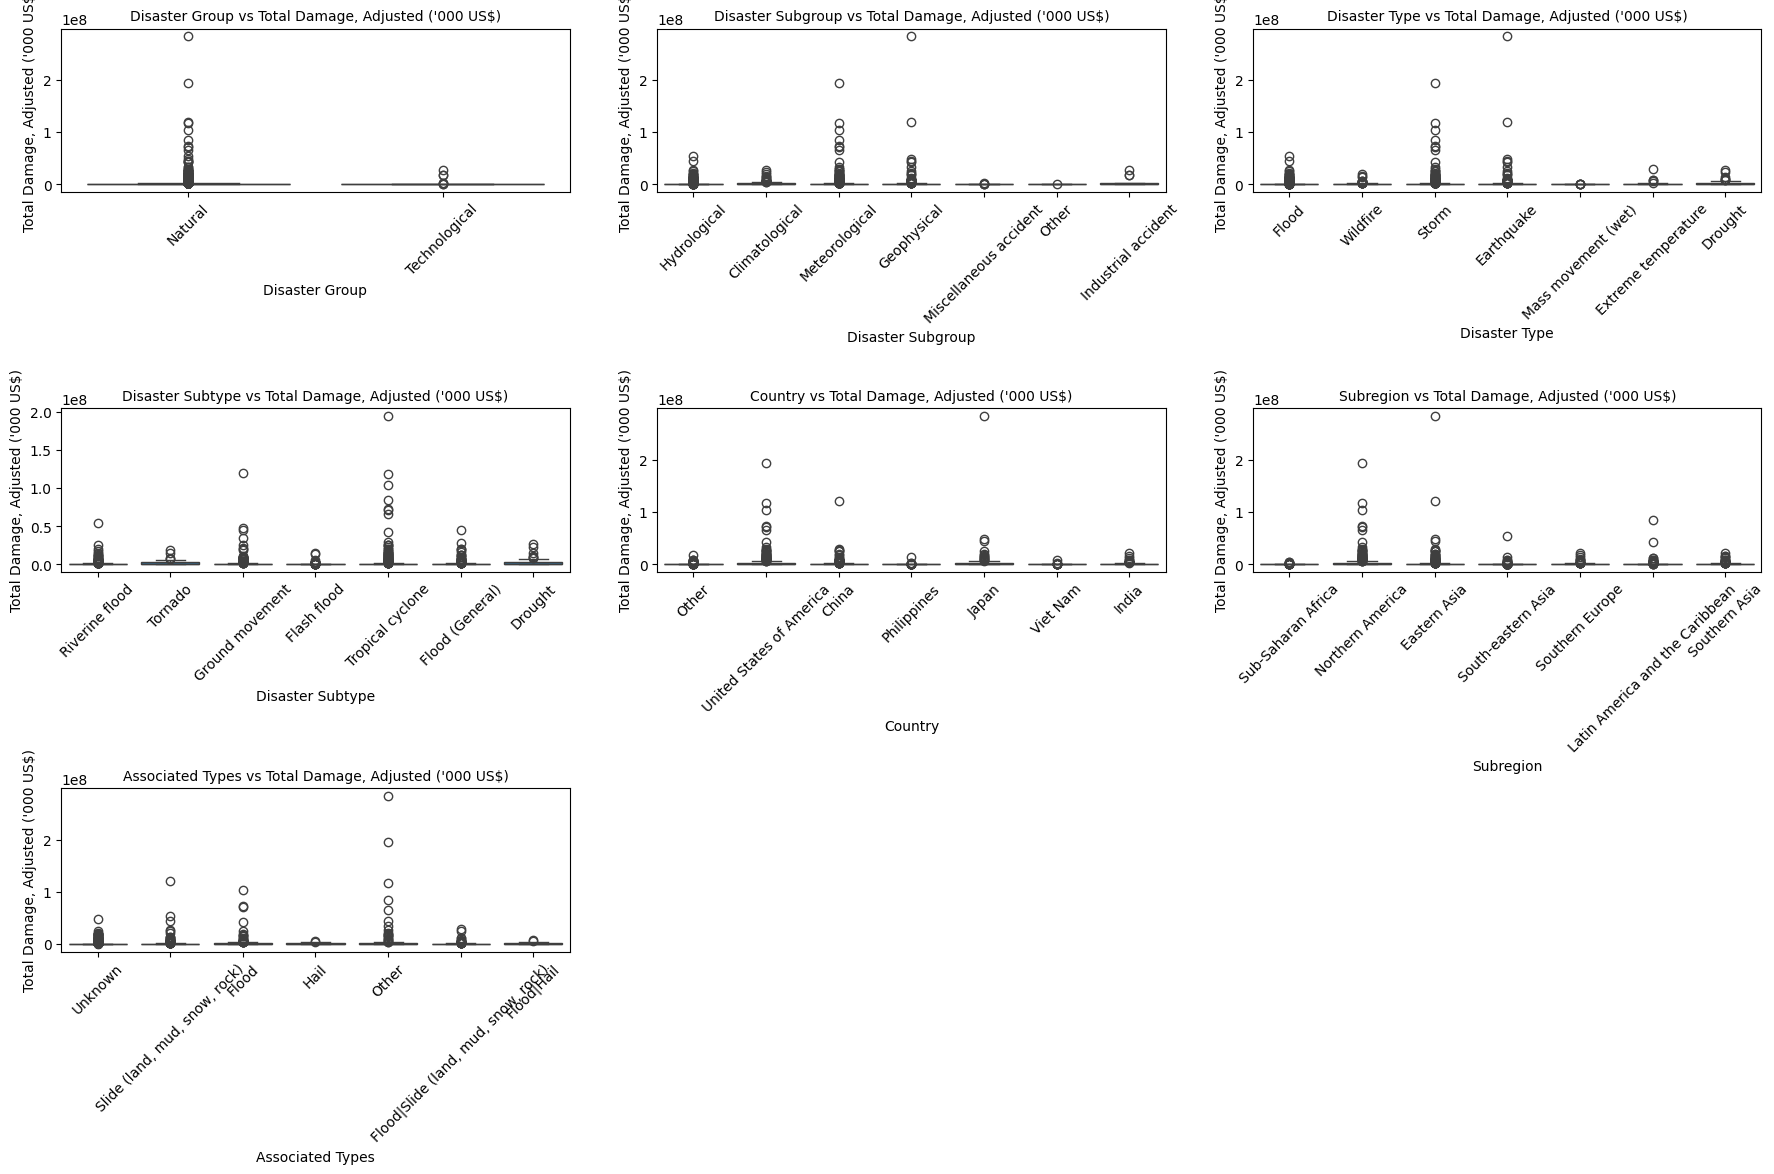

Fitting 3 folds for each of 12 candidates, totalling 36 fits


/usr/local/lib/python3.12/dist-packages/sklearn/feature_selection/_univariate_selection.py:783: UserWarning: k=150 is greater than n_features=75. All the features will be returned.
  warnings.warn(



Training Gradient Boosting...
Gradient Boosting Performance:
- MSE: 44,932,661,578,081
- RMSE: 6,703,183
- MAE: 1,253,230
- R²: 0.3121
- Adj. R²: 0.2176

Training XGBoost...
XGBoost Performance:
- MSE: 27,011,253,598,925
- RMSE: 5,197,235
- MAE: 1,131,471
- R²: 0.5865
- Adj. R²: 0.5297

Training Random Forest...
Random Forest Performance:
- MSE: 48,033,077,156,385
- RMSE: 6,930,590
- MAE: 1,238,203
- R²: 0.2646
- Adj. R²: 0.1636

Training Ridge (Optimized)...
Ridge (Optimized) Performance:
- MSE: 67,135,543,192,961
- RMSE: 8,193,628
- MAE: 1,537,557
- R²: -0.0278
- Adj. R²: -0.1690


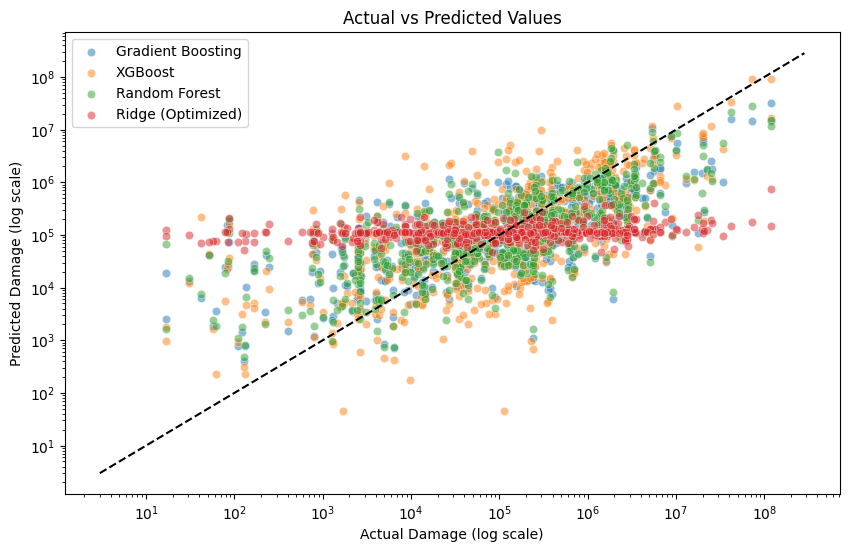

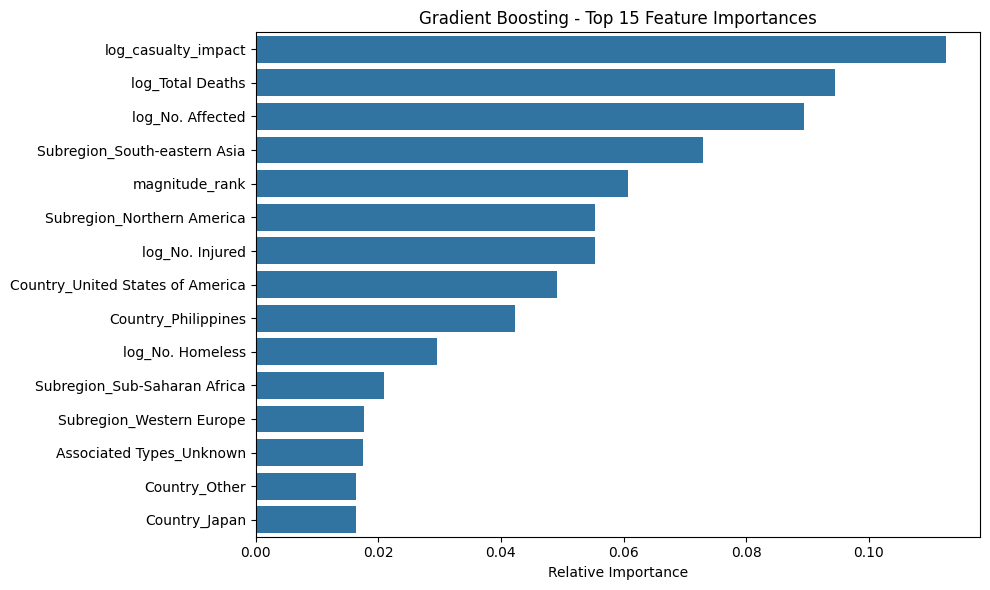

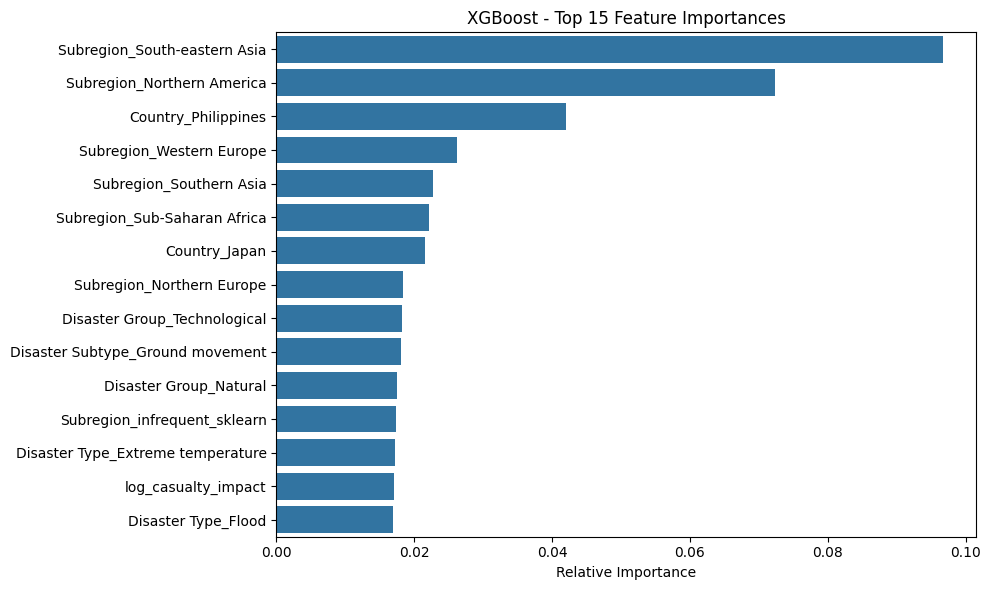

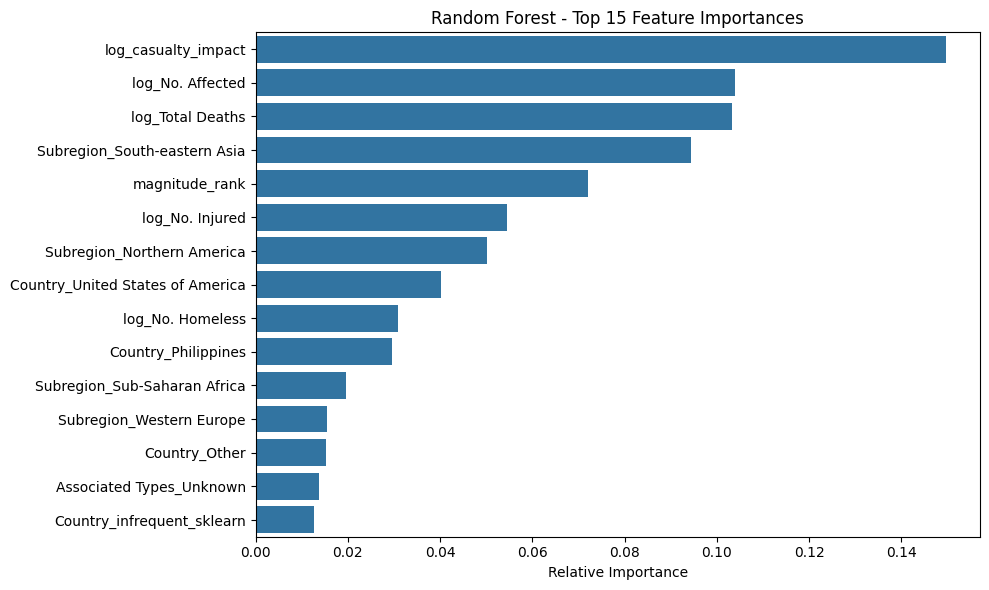


Percentage of disasters with Economic Impact Ratio > 2:
Gradient Boosting: 13.67%
XGBoost: 14.63%
Random Forest: 13.67%
Ridge (Optimized): 16.40%
Actual: 15.76%


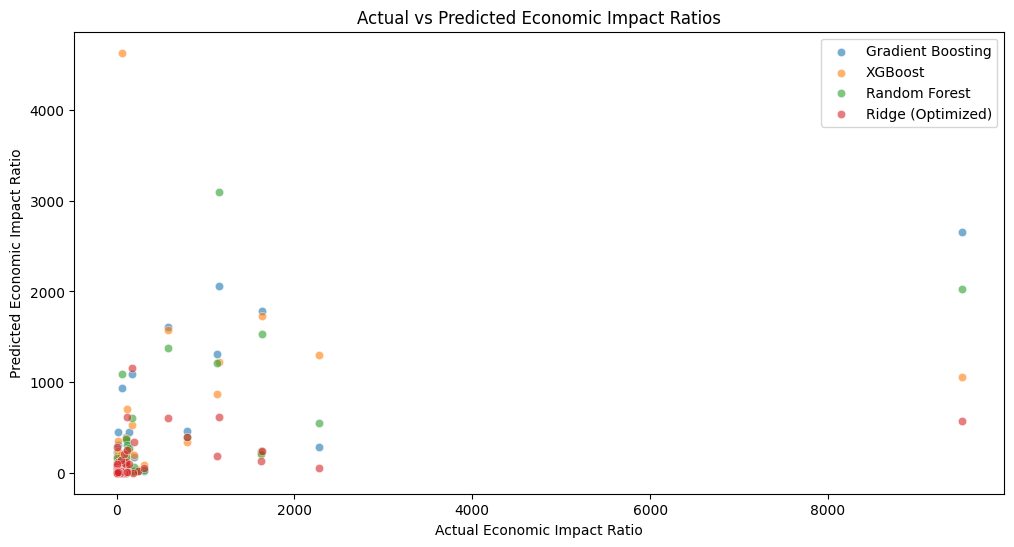

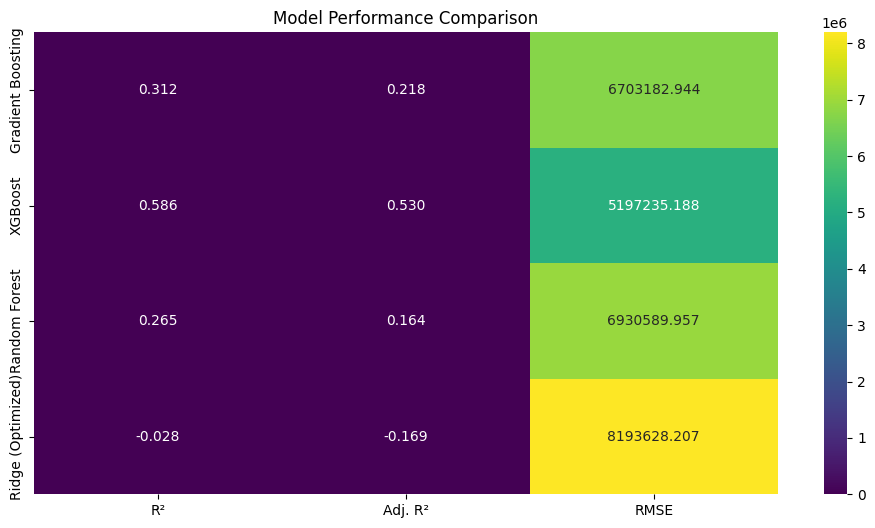

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import OneHotEncoder, RobustScaler
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
from sklearn import set_config
from sklearn.linear_model import Ridge
from xgboost import XGBRegressor
from sklearn.feature_selection import SelectKBest, mutual_info_regression

# Pandas output for sklearn pipelines
set_config(transform_output="pandas")

# Load and filter data
emdat = pd.read_excel('public_emdat_incl_hist_2025-04-07.xlsx')
emdat = emdat[
    (emdat['Year'] >= 2000) &
    (emdat['Disaster Type'] != 'Technological') &
    (emdat["Total Damage, Adjusted ('000 US$)"].notna())
].copy()

# Feature engineering
emdat['casualty_impact'] = emdat['Total Deaths'] * (emdat['No. Affected'] + 1)
skewed_features = ['Total Deaths', 'No. Injured', 'No. Affected', 'No. Homeless', 'casualty_impact']
for feat in skewed_features:
    emdat[f'log_{feat}'] = np.log1p(emdat[feat])

categorical_features = [
    'Disaster Group', 'Disaster Subgroup',
    'Disaster Type', 'Disaster Subtype', 'Country'
]
numerical_features = [f'log_{feat}' for feat in skewed_features]

for col in ['Subregion', 'Associated Types']:
    if col in emdat.columns:
        categorical_features.append(col)

if 'Magnitude' in emdat.columns:
    emdat['Magnitude'] = pd.to_numeric(emdat['Magnitude'], errors='coerce')
    emdat['magnitude_rank'] = emdat.groupby('Disaster Type')['Magnitude'].transform(
        lambda x: x.rank(pct=True) if x.notna().sum() > 5
        else 0.5
    )
    numerical_features.append('magnitude_rank')

# Handle missing values
for feature in numerical_features:
    if feature in emdat.columns:
        grp_median = emdat.groupby('Disaster Type')[feature].transform('median')
        emdat[feature] = emdat[feature].fillna(grp_median).fillna(emdat[feature].median())
for feature in categorical_features:
    counts = emdat[feature].value_counts()
    emdat[feature] = emdat[feature].mask(emdat[feature].isin(counts[counts < 10].index), 'Other')
    emdat[feature] = emdat[feature].fillna('Unknown')

# --- Feature visualization ---
def plot_feature_relationships(df, numerical_features, categorical_features, target):
    plt.figure(figsize=(18, 12))
    for i, feat in enumerate(numerical_features, 1):
        plt.subplot(3, 3, i)
        sns.regplot(x=df[feat], y=df[target], scatter_kws={'alpha':0.3}, line_kws={'color':'red'})
        plt.title(f"{feat} vs {target}", fontsize=10)
    plt.tight_layout()
    plt.show()

    plt.figure(figsize=(18, 12))
    for i, feat in enumerate(categorical_features, 1):
        plt.subplot(3, 3, i)
        top_cats = df[feat].value_counts().index[:7]
        filtered_df = df[df[feat].isin(top_cats)]
        sns.boxplot(x=feat, y=target, data=filtered_df)
        plt.xticks(rotation=45)
        plt.title(f"{feat} vs {target}", fontsize=10)
    plt.tight_layout()
    plt.show()

target = "Total Damage, Adjusted ('000 US$)"
plot_feature_relationships(emdat, numerical_features, categorical_features, target)

# --- Preprocessing pipeline ---
preprocessor = ColumnTransformer([
    ('cat', OneHotEncoder(
        handle_unknown='infrequent_if_exist',
        min_frequency=30,
        sparse_output=False
    ), categorical_features),
    ('num', RobustScaler(), numerical_features)
], remainder='drop')

X = emdat[categorical_features + numerical_features]
y = emdat[target]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# --- Models ---
models = {
    'Gradient Boosting': GradientBoostingRegressor(
        n_estimators=1000, learning_rate=0.05, max_depth=7,
        subsample=0.8, max_features='sqrt', random_state=42,
        validation_fraction=0.1, n_iter_no_change=15
    ),
    'XGBoost': XGBRegressor(
        n_estimators=1200, learning_rate=0.08, max_depth=8,
        subsample=0.7, colsample_bytree=0.7, reg_alpha=0.1,
        reg_lambda=0.1, random_state=42
    ),
    'Random Forest': RandomForestRegressor(
        n_estimators=800, max_depth=15, min_samples_split=8,
        max_features=0.6, random_state=42, bootstrap=True
    )
}

# --- Ridge Regression with tuning ---
ridge_pipe = make_pipeline(
    preprocessor,
    SelectKBest(score_func=mutual_info_regression),
    TransformedTargetRegressor(
        regressor=Ridge(),
        func=np.log1p,
        inverse_func=np.expm1
    )
)
ridge_params = {
    'selectkbest__k': [100, 150],
    'transformedtargetregressor__regressor__alpha': [1e5, 1e6, 1e7],
    'transformedtargetregressor__regressor__solver': ['sag', 'sparse_cg']
}
ridge_search = GridSearchCV(
    ridge_pipe,
    ridge_params,
    cv=3,
    scoring='neg_mean_squared_error',
    n_jobs=-1,
    verbose=1
)
ridge_search.fit(X_train, y_train)
models['Ridge (Optimized)'] = ridge_search.best_estimator_

# --- Model evaluation ---
def adjusted_r2(r2, n, k):
    return 1 - (1 - r2) * (n - 1) / (n - k - 1)

preprocessor.fit(X_train)
n_features = preprocessor.transform(X_train).shape[1]
results = {}

for model_name, estimator in models.items():
    print(f"\nTraining {model_name}...")
    try:
        if 'Ridge' in model_name:
            pipeline = estimator
            y_pred = pipeline.predict(X_test)
        else:
            pipeline = make_pipeline(
                preprocessor,
                TransformedTargetRegressor(
                    regressor=estimator,
                    func=np.log1p,
                    inverse_func=np.expm1
                )
            )
            pipeline.fit(X_train, y_train)
            y_pred = pipeline.predict(X_test)
        mse = mean_squared_error(y_test, y_pred)
        rmse = np.sqrt(mse)
        mae = mean_absolute_error(y_test, y_pred)
        r2 = r2_score(y_test, y_pred)
        adj_r2 = adjusted_r2(r2, len(y_test), n_features)
        results[model_name] = {
            'metrics': {'MSE': mse, 'RMSE': rmse, 'MAE': mae, 'R²': r2, 'Adj. R²': adj_r2},
            'predictions': y_pred,
            'pipeline': pipeline
        }
        print(f"{model_name} Performance:")
        print(f"- MSE: {mse:,.0f}")
        print(f"- RMSE: {rmse:,.0f}")
        print(f"- MAE: {mae:,.0f}")
        print(f"- R²: {r2:.4f}")
        print(f"- Adj. R²: {adj_r2:.4f}")
    except Exception as e:
        print(f"Error training {model_name}: {str(e)}")
        continue

# --- Actual vs Predicted Plot ---
plt.figure(figsize=(10, 6))
for model_name, res in results.items():
    sns.scatterplot(x=y_test, y=res['predictions'], alpha=0.5, label=model_name)
plt.plot([y.min(), y.max()], [y.min(), y.max()], 'k--')
plt.xlabel('Actual Damage (log scale)')
plt.ylabel('Predicted Damage (log scale)')
plt.xscale('log')
plt.yscale('log')
plt.title('Actual vs Predicted Values')
plt.legend()
plt.show()

# --- Feature Importance Bar Plots ---
cat_names = preprocessor.named_transformers_['cat'].get_feature_names_out(categorical_features)
feature_names = np.concatenate([cat_names, numerical_features])
for model_name, res in results.items():
    try:
        model = res['pipeline'][-1].regressor_
        if hasattr(model, "feature_importances_"):
            importances = model.feature_importances_
            sorted_idx = np.argsort(importances)[::-1][:15]
            plt.figure(figsize=(10, 6))
            sns.barplot(
                x=importances[sorted_idx],
                y=feature_names[sorted_idx],
                orient='h'
            )
            plt.title(f"{model_name} - Top 15 Feature Importances")
            plt.xlabel("Relative Importance")
            plt.tight_layout()
            plt.show()
    except Exception as e:
        print(f"{model_name} does not support feature importance: {e}")

# --- Create predictions_df DataFrame ---
predictions_df = pd.DataFrame({
    'Actual_Damage': y_test.values,
    'casualty_impact': emdat.loc[y_test.index, 'casualty_impact'].values
})
for model_name, res in results.items():
    predictions_df[f'{model_name}_Prediction'] = res['predictions']

# --- Economic Impact Ratio calculations ---
for model_name in models:
    predictions_df[f'{model_name}_Economic_Impact_Ratio'] = (
        predictions_df[f'{model_name}_Prediction'] /
        (predictions_df['casualty_impact'] + 1)
    )

predictions_df['Actual_Economic_Impact_Ratio'] = (
    predictions_df['Actual_Damage'] /
    (predictions_df['casualty_impact'] + 1)
)

print("\nPercentage of disasters with Economic Impact Ratio > 2:")
for model_name in models:
    pct_above_2 = (predictions_df[f'{model_name}_Economic_Impact_Ratio'] > 2).mean() * 100
    print(f"{model_name}: {pct_above_2:.2f}%")
print(f"Actual: {(predictions_df['Actual_Economic_Impact_Ratio'] > 2).mean() * 100:.2f}%")

plt.figure(figsize=(12, 6))
for model_name in models:
    sns.scatterplot(
        x=predictions_df['Actual_Economic_Impact_Ratio'],
        y=predictions_df[f'{model_name}_Economic_Impact_Ratio'],
        alpha=0.6,
        label=model_name
    )
plt.xlabel('Actual Economic Impact Ratio')
plt.ylabel('Predicted Economic Impact Ratio')
plt.title('Actual vs Predicted Economic Impact Ratios')
plt.legend()
plt.show()

# --- Model Performance Heatmap ---
metrics_df = pd.DataFrame({model: res['metrics'] for model, res in results.items()}).T
plt.figure(figsize=(12, 6))
sns.heatmap(metrics_df[['R²', 'Adj. R²', 'RMSE']], annot=True, fmt=".3f", cmap='viridis')
plt.title('Model Performance Comparison')
plt.show()

# --- Save results ---
predictions_df.to_csv('disaster_predictions_with_economic_impact.csv', index=False)
metrics_df.to_csv('model_performance_metrics.csv')
